# Training Pipeline for Glioma Grading

This notebook trains classification models on the preprocessed glioma dataset and mirrors the model family reported in the attached paper:
- Perceptron
- Logistic Regression
- K-Nearest Neighbors (KNN)
- Decision Tree
- Support Vector Machine (SVM)

Paper-aligned outputs include:
- Training accuracy
- Testing accuracy
- Confusion matrix

Additional clinical metrics are also reported: sensitivity, specificity, PPV, NPV, F1, and AUC.

In [1]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    classification_report
 )

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.linear_model import Perceptron

import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", None)

In [ ]:
DATA_PATH = "./data/preprocessed/3_glioma_grading_clinical_and_mutation_features_preprocessed_df.csv"
LABEL = "Grade"

df = pd.read_csv(DATA_PATH)
display(df.head())

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

X = df.drop(columns=[LABEL])
y = df[LABEL].astype(int)

print("Class distribution:")
display(y.value_counts().sort_index())

,Grade,Gender,Age_at_diagnosis,Race,IDH1,TP53,ATRX,PTEN,EGFR,CIC,MUC16,PIK3CA,NF1,PIK3R1,FUBP1,RB1,NOTCH1,BCOR,CSMD3,SMARCA4,GRIN2A,IDH2,FAT4,PDGFRA
0,0,0,51.30,0,1,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0
1,0,0,38.72,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,35.17,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,1,32.78,0,1,1,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,1,0
4,0,0,31.51,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Shape: (838, 24)
Columns: ['Grade', 'Gender', 'Age_at_diagnosis', 'Race', 'IDH1', 'TP53', 'ATRX', 'PTEN', 'EGFR', 'CIC', 'MUC16', 'PIK3CA', 'NF1', 'PIK3R1', 'FUBP1', 'RB1', 'NOTCH1', 'BCOR', 'CSMD3', 'SMARCA4', 'GRIN2A', 'IDH2', 'FAT4', 'PDGFRA']
Class distribution:


Grade
0    486
1    352
Name: count, dtype: int64

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (670, 23)
Test shape: (168, 23)


In [4]:
def binary_specificity(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tn / (tn + fp) if (tn + fp) else np.nan

def evaluate_binary_model(model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)

    y_pred_train = model.predict(X_tr)
    y_pred_test = model.predict(X_te)

    train_acc = accuracy_score(y_tr, y_pred_train)
    test_acc = accuracy_score(y_te, y_pred_test)

    cm = confusion_matrix(y_te, y_pred_test)

    sensitivity = recall_score(y_te, y_pred_test)
    specificity = binary_specificity(y_te, y_pred_test)
    ppv = precision_score(y_te, y_pred_test, zero_division=0)
    npv = cm[0, 0] / (cm[0, 0] + cm[1, 0]) if (cm[0, 0] + cm[1, 0]) else np.nan
    f1 = f1_score(y_te, y_pred_test)

    y_score = None
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_te)[:, 1]
    elif hasattr(model, "decision_function"):
        y_score = model.decision_function(X_te)

    auc = roc_auc_score(y_te, y_score) if y_score is not None else np.nan

    return {
        "Train_Accuracy": train_acc,
        "Test_Accuracy": test_acc,
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "PPV": ppv,
        "NPV": npv,
        "F1": f1,
        "AUC": auc,
        "Confusion_Matrix": cm.tolist(),
    }, y_pred_test, cm

In [ ]:
models = {
    "Perceptron": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", Perceptron(max_iter=2000, tol=1e-3, random_state=SEED))
    ]),
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=5000, random_state=SEED))
    ]),
    "K-Neighbors Classifier": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=9))
    ]),
    "Decision Tree Classifier": DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=4,
        random_state=SEED
    ),
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", SVC(kernel="rbf", C=3.0, gamma="scale", probability=True, random_state=SEED))
    ]),
}

rows = []
conf_mats = {}

for model_name, model in models.items():
    metrics_row, y_pred, cm = evaluate_binary_model(model, X_train, y_train, X_test, y_test)
    rows.append({"Model": model_name, **metrics_row})
    conf_mats[model_name] = cm

results_df = pd.DataFrame(rows).sort_values(["Test_Accuracy", "Train_Accuracy"], ascending=False).reset_index(drop=True)

paper_cols = ["Model", "Train_Accuracy", "Test_Accuracy", "Confusion_Matrix"]
display(
    results_df[paper_cols].style.format({
        "Train_Accuracy": "{:.4f}",
        "Test_Accuracy": "{:.4f}"
    })
)

print("\nExtended metrics:")
extended_cols = ["Model", "Sensitivity", "Specificity", "PPV", "NPV", "F1", "AUC"]
display(results_df[extended_cols].style.format({c: "{:.4f}" for c in extended_cols if c != "Model"}))

,Model,Train_Accuracy,Test_Accuracy,Confusion_Matrix
0,Logistic Regression,0.8821,0.8631,"[[83, 14], [9, 62]]"
1,Perceptron,0.8239,0.8452,"[[78, 19], [7, 64]]"
2,SVM,0.9075,0.8393,"[[82, 15], [12, 59]]"
3,Decision Tree Classifier,0.8881,0.8393,"[[79, 18], [9, 62]]"
4,K-Neighbors Classifier,0.8567,0.8333,"[[76, 21], [7, 64]]"



Extended metrics:


,Model,Sensitivity,Specificity,PPV,NPV,F1,AUC
0,Logistic Regression,0.8732,0.8557,0.8158,0.9022,0.8435,0.9172
1,Perceptron,0.9014,0.8041,0.7711,0.9176,0.8312,0.8939
2,SVM,0.8310,0.8454,0.7973,0.8723,0.8138,0.8985
3,Decision Tree Classifier,0.8732,0.8144,0.7750,0.8977,0.8212,0.9030
4,K-Neighbors Classifier,0.9014,0.7835,0.7529,0.9157,0.8205,0.8887


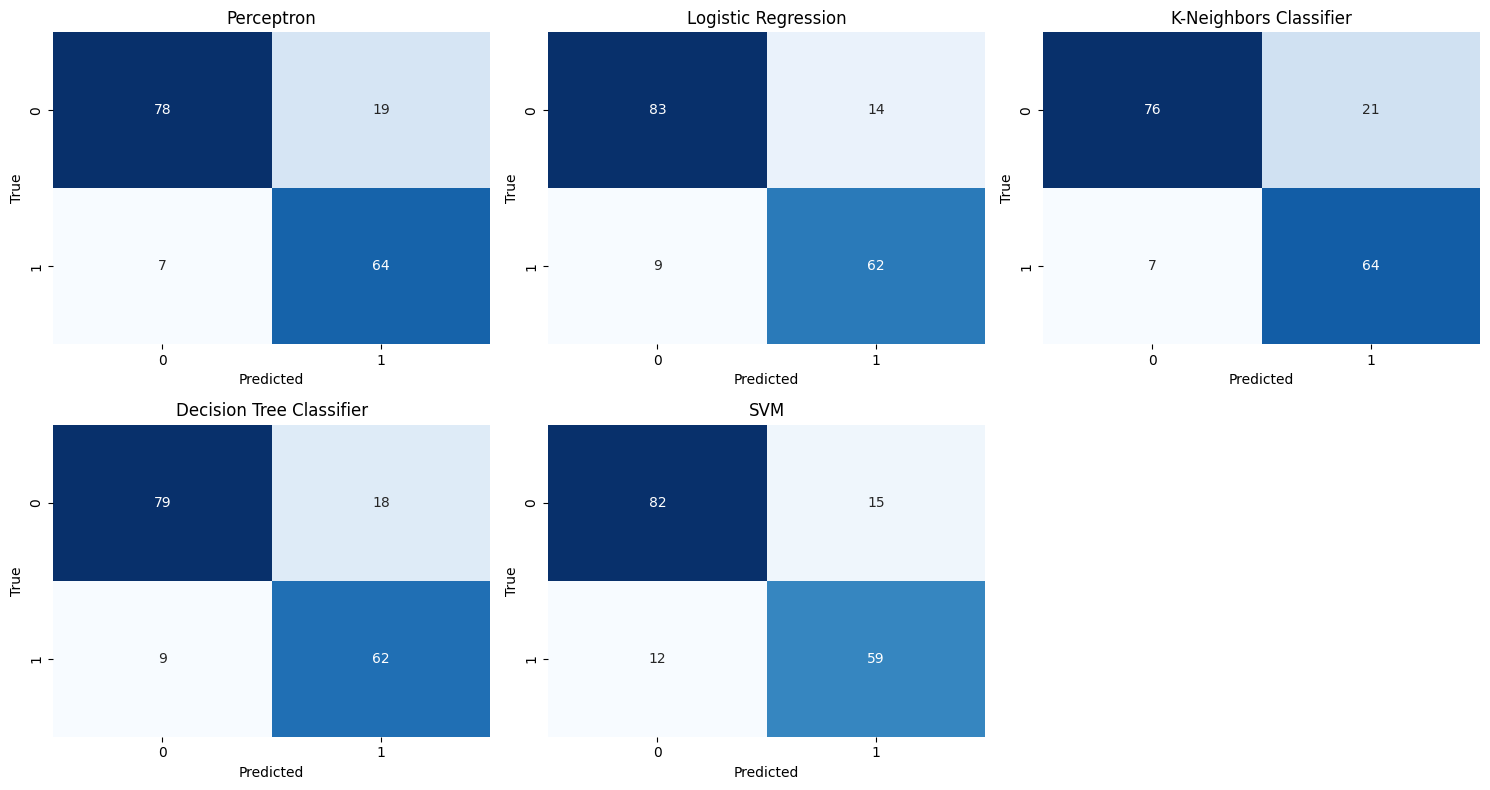

In [ ]:
# confusion matrixes for all models
n_models = len(conf_mats)
ncols = 3
nrows = int(np.ceil(n_models / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
axes = np.array(axes).reshape(-1)

for ax, (model_name, cm) in zip(axes, conf_mats.items()):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(model_name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")

for ax in axes[n_models:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
best_idx = results_df["Test_Accuracy"].idxmax()
best_model_name = results_df.loc[best_idx, "Model"]
best_model = models[best_model_name]

best_model.fit(X_train, y_train)
y_pred_best = best_model.predict(X_test)

print(f"Best model: {best_model_name}")
print(classification_report(y_test, y_pred_best, digits=4))

Best model: Logistic Regression
              precision    recall  f1-score   support

           0     0.9022    0.8557    0.8783        97
           1     0.8158    0.8732    0.8435        71

    accuracy                         0.8631       168
   macro avg     0.8590    0.8645    0.8609       168
weighted avg     0.8657    0.8631    0.8636       168

